# Chapter 7: Multiplication Scales, Division Asks

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** see every product as two roles (how many groups, how many in each), see why signs work the way they do in a product, and see division as the question of which role is missing.

The code cells are optional reading. You do not need to run anything or follow the code: the results and the pictures are shown right below each cell. If you do want to peek, each code cell redoes the arithmetic one substitution at a time, the way you would on paper.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
%matplotlib inline

# Colors used in every picture
TEAL = "#1f7a7a"
TERRACOTTA = "#c25b3f"
NAVY = "#24344d"
GOLD = "#d9a441"
LIGHT = "#cfd6dd"
INK = "#1d1d1d"

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11})

def fmt(n):
    """Whole number with commas, like 5,084,000."""
    return f"{int(n):,}"

def signed(n):
    """Show a plus sign on positive numbers: +11, -4, 0."""
    return f"+{n}" if n > 0 else str(n)

## Demonstration 1: An array shows the roles

**Question in plain words:** In $6 \times 8 = 48$, which number counts rows, which counts tiles per row, and what happens if one of them doubles?

$$6 \times 8 = 48$$

**What the symbols mean:**
- The first factor counts **rows**. The second counts **tiles in each row**. The product counts **tiles**.
- Each row is one equal group, so the total is rows times tiles per row.
- Doubling the rows doubles the total. Turning the array around swaps the roles but not the count.

**Predict first:** keep 8 tiles per row and go from 6 rows to 12. How many tiles will there be?

In [2]:
def array(rows, per_row):
    total = rows * per_row
    print(f"{rows} x {per_row} = {total} tiles")
    print("  As repeated addition: " + " + ".join([str(per_row)] * rows) + f" = {total}")
    diff = total - 48
    if diff == 0:
        cmp = "same as 48"
    elif total % 48 == 0:
        cmp = f"{total // 48} x 48"
    elif diff < 0:
        cmp = f"{-diff} fewer than 48"
    else:
        cmp = f"{diff} more than 48"
    print(f"  Compared with 6 x 8 = 48: {cmp}")
    print()

array(6, 8)
print("Other menu values:\n")
for r, p in [(12, 8), (8, 6), (6, 6), (12, 6), (8, 8)]:
    array(r, p)

6 x 8 = 48 tiles
  As repeated addition: 8 + 8 + 8 + 8 + 8 + 8 = 48
  Compared with 6 x 8 = 48: same as 48

Other menu values:

12 x 8 = 96 tiles
  As repeated addition: 8 + 8 + 8 + 8 + 8 + 8 + 8 + 8 + 8 + 8 + 8 + 8 = 96
  Compared with 6 x 8 = 48: 2 x 48

8 x 6 = 48 tiles
  As repeated addition: 6 + 6 + 6 + 6 + 6 + 6 + 6 + 6 = 48
  Compared with 6 x 8 = 48: same as 48

6 x 6 = 36 tiles
  As repeated addition: 6 + 6 + 6 + 6 + 6 + 6 = 36
  Compared with 6 x 8 = 48: 12 fewer than 48

12 x 6 = 72 tiles
  As repeated addition: 6 + 6 + 6 + 6 + 6 + 6 + 6 + 6 + 6 + 6 + 6 + 6 = 72
  Compared with 6 x 8 = 48: 24 more than 48

8 x 8 = 64 tiles
  As repeated addition: 8 + 8 + 8 + 8 + 8 + 8 + 8 + 8 = 64
  Compared with 6 x 8 = 48: 16 more than 48



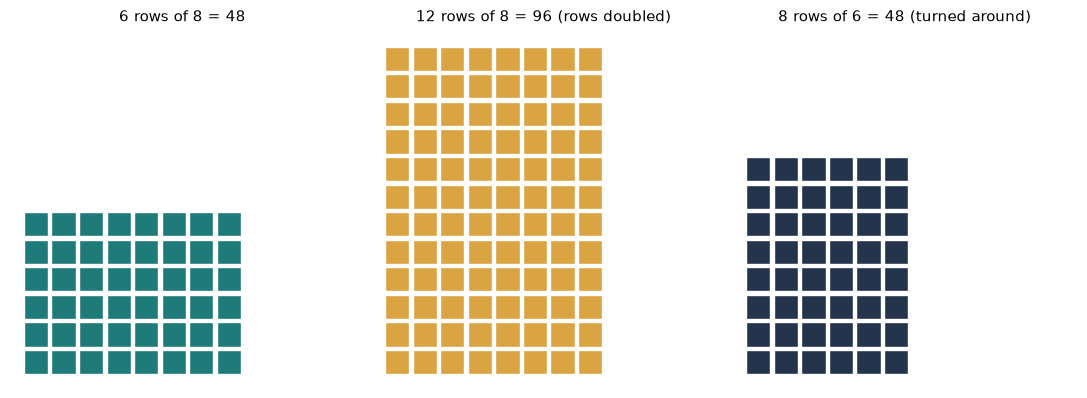

In [3]:
def draw_array(ax, rows, per_row, color, title):
    for r in range(rows):
        for c in range(per_row):
            ax.add_patch(Rectangle((c, rows - 1 - r), 0.88, 0.88, facecolor=color, edgecolor="white"))
    ax.set_xlim(-0.5, 12); ax.set_ylim(-0.5, 12.5); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=11)

fig, axes = plt.subplots(1, 3, figsize=(11, 4.2))
draw_array(axes[0], 6, 8, TEAL, "6 rows of 8 = 48")
draw_array(axes[1], 12, 8, GOLD, "12 rows of 8 = 96 (rows doubled)")
draw_array(axes[2], 8, 6, NAVY, "8 rows of 6 = 48 (turned around)")
plt.tight_layout(); plt.show()

**What this shows.** $6 \times 8 = 48$, and as repeated addition $8 + 8 + 8 + 8 + 8 + 8 = 48$. One factor counts rows, the other counts tiles in each row. When you multiply, say what each factor counts, with its unit, and the unit of the product comes for free.

**Where it stops working.** Every row has to hold the same number of tiles, and both factors are positive whole numbers. A ragged arrangement may hold 48 tiles but no longer shows 6 equal groups of 8.

## Demonstration 2: Signs in a product

**Question in plain words:** Why is $(-5)(6)$ negative while $(-5)(-6)$ is positive?

$$(-5)(6) = -30 \qquad\qquad (-5)(-6) = 30$$

**What the symbols mean:**
- Two numbers in parentheses side by side are multiplied.
- The **magnitude** is the size without the sign. Multiply the magnitudes first, then choose the sign: different signs give a negative product, equal signs a positive one.
- A factor and its opposite give products that cancel, because $6 + (-6) = 0$.

**Predict first:** change the second factor from 6 to $-6$. Which way will the arrow point?

In [4]:
def sign_product(a, b):
    ma, mb = abs(a), abs(b)
    prod = a * b
    print(f"({a})({b})")
    print(f"  Magnitudes first: {ma} x {mb} = {ma * mb}")
    if prod == 0:
        print("  Zero has no sign, so the product is simply 0.")
    else:
        same = (a > 0) == (b > 0)
        print(f"  Signs: {'equal, so positive' if same else 'different, so negative'}")
    print(f"  Product: ({a}) x ({b}) = {prod}")
    if b != 0:
        opp = a * (-b)
        print(f"  Pair check with the opposite factor: ({a}) x ({-b}) = {opp}, and {prod} + ({opp}) = {prod + opp}")
        print(f"  Because ({a}) x ({b} + ({-b})) = ({a}) x 0 = 0")
    print()

sign_product(-5, 6)
print("Other menu values:\n")
for a, b in [(-5, -6), (-5, 0), (5, 6), (5, -6), (5, 0)]:
    sign_product(a, b)

(-5)(6)
  Magnitudes first: 5 x 6 = 30
  Signs: different, so negative
  Product: (-5) x (6) = -30
  Pair check with the opposite factor: (-5) x (-6) = 30, and -30 + (30) = 0
  Because (-5) x (6 + (-6)) = (-5) x 0 = 0

Other menu values:

(-5)(-6)
  Magnitudes first: 5 x 6 = 30
  Signs: equal, so positive
  Product: (-5) x (-6) = 30
  Pair check with the opposite factor: (-5) x (6) = -30, and 30 + (-30) = 0
  Because (-5) x (-6 + (6)) = (-5) x 0 = 0

(-5)(0)
  Magnitudes first: 5 x 0 = 0
  Zero has no sign, so the product is simply 0.
  Product: (-5) x (0) = 0

(5)(6)
  Magnitudes first: 5 x 6 = 30
  Signs: equal, so positive
  Product: (5) x (6) = 30
  Pair check with the opposite factor: (5) x (-6) = -30, and 30 + (-30) = 0
  Because (5) x (6 + (-6)) = (5) x 0 = 0

(5)(-6)
  Magnitudes first: 5 x 6 = 30
  Signs: different, so negative
  Product: (5) x (-6) = -30
  Pair check with the opposite factor: (5) x (6) = 30, and -30 + (30) = 0
  Because (5) x (-6 + (6)) = (5) x 0 = 0

(5)(0)


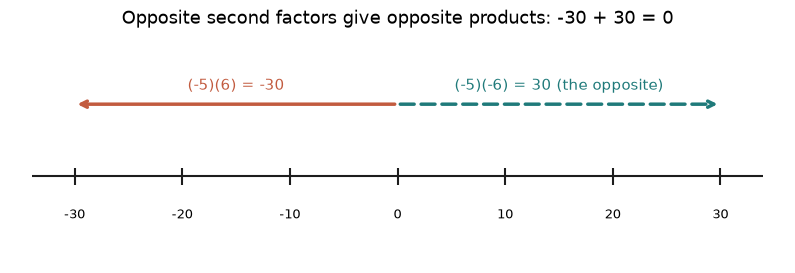

In [5]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.hlines(0, -34, 34, color=INK)
for t in range(-30, 31, 10):
    ax.vlines(t, -0.12, 0.12, color=INK)
    ax.text(t, -0.45, str(t), ha="center", va="top", fontsize=9)
ax.annotate("", xy=(-30, 1.0), xytext=(0, 1.0), arrowprops=dict(arrowstyle="->", color=TERRACOTTA, linewidth=2.5))
ax.text(-15, 1.2, "(-5)(6) = -30", ha="center", color=TERRACOTTA)
ax.annotate("", xy=(30, 1.0), xytext=(0, 1.0), arrowprops=dict(arrowstyle="->", color=TEAL, linewidth=2.5, linestyle=(0, (4, 2))))
ax.text(15, 1.2, "(-5)(-6) = 30 (the opposite)", ha="center", color=TEAL)
ax.set_xlim(-36, 36); ax.set_ylim(-1.2, 2); ax.axis("off")
ax.set_title("Opposite second factors give opposite products: -30 + 30 = 0")
plt.show()

**What this shows.** Magnitudes first: $5 \times 6 = 30$. The signs differ, so the product is negative: $(-5)(6) = -30$. With the opposite factor, $(-5)(-6) = 30$, and the pair adds to zero, just as $(-5)(6 + (-6)) = (-5)(0) = 0$. When a sign is uncertain, write the magnitudes and the signs separately, then check that the opposite factor gives the opposite product.

**Where it stops working.** This is for signed whole-number factors and the distributive rule. Zero has no sign, so a product with a zero factor is simply 0 (and there is no opposite pair to draw).

## Demonstration 3: Sharing or grouping?

**Question in plain words:** 48 tiles, boxes, and the numbers 6 and 8. Which division question is being asked?

$$48 \div 6 = 8 \qquad\qquad 48 \div 8 = 6$$

**What the symbols mean:**
- **Sharing** division knows the number of boxes and finds tiles per box. **Grouping** division knows tiles per box and finds the number of boxes.
- Both come from one multiplication fact: boxes $\times$ tiles per box = tiles.
- The $\div$ sign and the $/$ sign in the calculations both mean divide.

**Predict first:** switch from sharing among 6 boxes to packing 8 tiles per box. Will the 48 tiles fill 6 boxes or 8?

In [6]:
def division(tiles, question):
    if question == "share":
        boxes = 6
        q = tiles // boxes
        print(f"Sharing {tiles} tiles among {boxes} boxes (group size unknown)")
        print(f"  {tiles} tiles / {boxes} boxes = {q} tiles per box")
        print(f"  Multiplication check: {boxes} x {q} = {boxes * q}")
    else:
        per = 8
        q = tiles // per
        print(f"Packing {tiles} tiles, {per} per box (number of groups unknown)")
        print(f"  {tiles} tiles / {per} tiles per box = {q} boxes")
        print(f"  Multiplication check: {q} x {per} = {q * per}")
    print()

division(48, "share")
print("Other menu values:\n")
division(48, "group")
division(24, "share")
division(24, "group")

Sharing 48 tiles among 6 boxes (group size unknown)
  48 tiles / 6 boxes = 8 tiles per box
  Multiplication check: 6 x 8 = 48

Other menu values:

Packing 48 tiles, 8 per box (number of groups unknown)
  48 tiles / 8 tiles per box = 6 boxes
  Multiplication check: 6 x 8 = 48

Sharing 24 tiles among 6 boxes (group size unknown)
  24 tiles / 6 boxes = 4 tiles per box
  Multiplication check: 6 x 4 = 24

Packing 24 tiles, 8 per box (number of groups unknown)
  24 tiles / 8 tiles per box = 3 boxes
  Multiplication check: 3 x 8 = 24



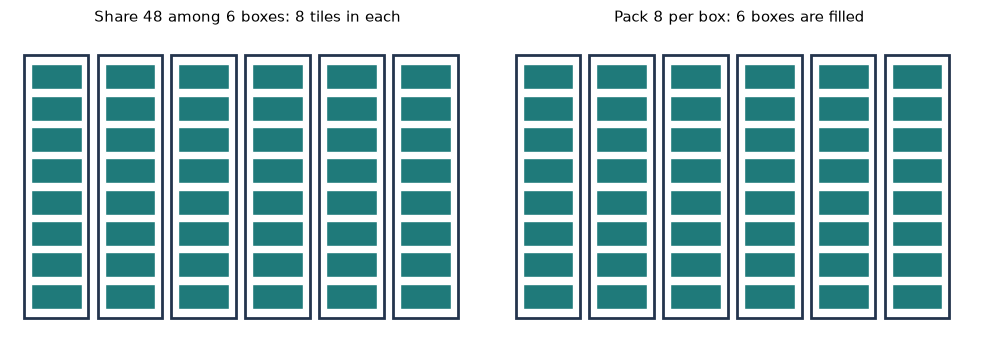

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (boxes, per, title) in zip(axes, [(6, 8, "Share 48 among 6 boxes: 8 tiles in each"),
                                          (6, 8, "Pack 8 per box: 6 boxes are filled")]):
    for b in range(boxes):
        ax.add_patch(Rectangle((b * 1.6, 0), 1.4, per * 0.5 + 0.2, fill=False, edgecolor=NAVY, linewidth=2))
        for t in range(per):
            ax.add_patch(Rectangle((b * 1.6 + 0.15, 0.15 + t * 0.5), 1.1, 0.4, facecolor=TEAL, edgecolor="white"))
    ax.set_xlim(-0.3, 10); ax.set_ylim(-0.3, 4.6); ax.axis("off")
    ax.set_title(title, fontsize=11)
plt.tight_layout(); plt.show()

**What this shows.** $48 \text{ tiles} / 6 \text{ boxes} = 8 \text{ tiles per box}$, and the check is $6 \times 8 = 48$. The same multiplication fact answers both questions; the units tell you which number the quotient is. Before dividing, write the missing-factor sentence with a blank and its unit. The blank tells you whether the answer is a group size or a number of groups.

**Where it stops working.** Every box holds the same number of tiles and the division comes out even. If it does not, a remainder appears and the question must say what to do with it (the next demonstration).

## Demonstration 4: When something remains

**Question in plain words:** 53 cards go into groups of 8. Is the answer 6 or 7?

$$53 = 6 \times 8 + 5$$

**What the symbols mean:**
- The **quotient** counts complete groups. The **remainder** is what is left after making as many full groups as possible. Here it is always less than 8.
- Counting complete groups ignores the short row. Placing every card needs one more group for it.

**Predict first:** keep 53 cards and ask how many groups hold every card. Will the answer be 6 or 7?

In [8]:
def remainder(cards, question):
    q, r = divmod(cards, 8)
    print(f"{cards} cards in groups of 8")
    print(f"  {cards} / 8 = {q} remainder {r}")
    print(f"  {q} x 8 = {q * 8}, and {cards} - {q * 8} = {r} cards remain, which is less than 8")
    print(f"  Rebuild check: {q} x 8 + {r} = {q * 8 + r}")
    if question == "complete":
        print(f"  Complete groups: {q}" + (f", with {r} cards left over" if r else ""))
    else:
        total = q + (1 if r else 0)
        print(f"  Groups to hold every card: {total}" + (f" ({q} full and 1 short group of {r})" if r else " (it comes out even)"))
    print()

remainder(53, "complete")
print("Other menu values:\n")
remainder(53, "every")
for c in (48, 55, 56):
    remainder(c, "complete")
    remainder(c, "every")

53 cards in groups of 8
  53 / 8 = 6 remainder 5
  6 x 8 = 48, and 53 - 48 = 5 cards remain, which is less than 8
  Rebuild check: 6 x 8 + 5 = 53
  Complete groups: 6, with 5 cards left over

Other menu values:

53 cards in groups of 8
  53 / 8 = 6 remainder 5
  6 x 8 = 48, and 53 - 48 = 5 cards remain, which is less than 8
  Rebuild check: 6 x 8 + 5 = 53
  Groups to hold every card: 7 (6 full and 1 short group of 5)

48 cards in groups of 8
  48 / 8 = 6 remainder 0
  6 x 8 = 48, and 48 - 48 = 0 cards remain, which is less than 8
  Rebuild check: 6 x 8 + 0 = 48
  Complete groups: 6

48 cards in groups of 8
  48 / 8 = 6 remainder 0
  6 x 8 = 48, and 48 - 48 = 0 cards remain, which is less than 8
  Rebuild check: 6 x 8 + 0 = 48
  Groups to hold every card: 6 (it comes out even)

55 cards in groups of 8
  55 / 8 = 6 remainder 7
  6 x 8 = 48, and 55 - 48 = 7 cards remain, which is less than 8
  Rebuild check: 6 x 8 + 7 = 55
  Complete groups: 6, with 7 cards left over

55 cards in groups o

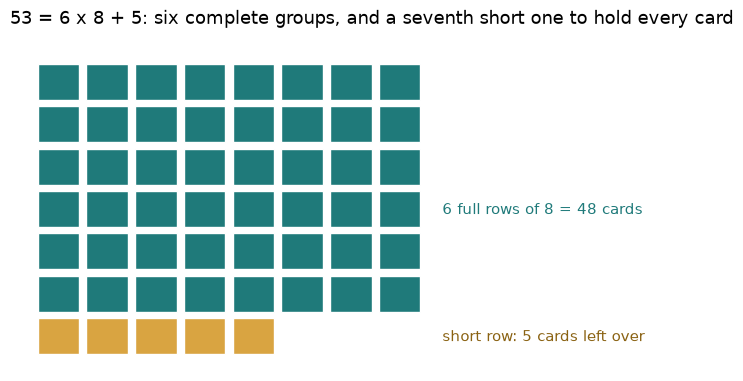

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.4))
cards = 53
for k in range(cards):
    r, c = divmod(k, 8)
    full = r < 6
    ax.add_patch(Rectangle((c, 6 - r), 0.85, 0.85, facecolor=TEAL if full else GOLD, edgecolor="white"))
ax.text(8.3, 3.4, "6 full rows of 8 = 48 cards", color=TEAL, va="center")
ax.text(8.3, 0.4, "short row: 5 cards left over", color="#8a6212", va="center")
ax.set_xlim(-0.3, 14); ax.set_ylim(-0.4, 7.6); ax.axis("off")
ax.set_title("53 = 6 x 8 + 5: six complete groups, and a seventh short one to hold every card")
plt.show()

**What this shows.** $6 \times 8 = 48$ and $53 - 48 = 5$, so $53 = 6 \times 8 + 5$. If only full groups count, the answer is 6, with 5 cards left over. If every card needs a place, the answer is 7. When a division leaves a remainder, reread the question before rounding: does it count full groups, or does every item need a place?

**Where it stops working.** This is for whole cards and a final group that may be incomplete. Some settings forbid an incomplete group or split the leftovers another way; the setting decides.

## Practice

**1.** An array has 7 rows of 9 tiles. How many tiles? How many with 14 rows of 9?

<details><summary>Show answer</summary>

7 x 9 = 63 tiles.
Doubling the rows: 14 x 9 = 126, and 2 x 63 = 126, so doubling the rows doubles the total.

</details>

**2.** What are $(-4)(3)$ and $(-4)(-3)$, and why must they add to zero?

<details><summary>Show answer</summary>

Magnitudes: 4 x 3 = 12. Different signs give (-4)(3) = -12. Equal signs give (-4)(-3) = 12.
They add to zero because (-4)(3 + (-3)) = (-4)(0) = 0, and also -12 + 12 = 0.

</details>

**3.** 72 labels go equally on 9 sheets. How many labels per sheet, and is that sharing or grouping?

<details><summary>Show answer</summary>

72 / 9 = 8 labels per sheet. Check: 9 x 8 = 72.
The number of sheets (9) is known and the group size is the unknown, so it is sharing.

</details>

**4.** 61 cards go into groups of 8. How many complete groups, and how many groups to hold every card?

<details><summary>Show answer</summary>

7 x 8 = 56 and 61 - 56 = 5, so 61 = 7 x 8 + 5.
That is 7 complete groups, and 8 groups to hold every card (the 8th holds the last 5).

</details>